In [20]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [3]:
df = pd.read_csv(r'C:\Users\Maria Paula Toro\Documents\Data Analyst\Banco\Base_Default.csv',encoding='latin-1')

In [4]:
df.head()

,Id,Ciudad,Departamento,Default,Edad,Ocupación,Estado Civil,Estudios,Tipo vivienda,Productos del pasivo
0,5055,Bogota,Bogota D.C,0,74,Pensionado,Casado,Profesional,Propia,2
1,5056,Girardot,Cundinamarca,0,72,Pensionado,Casado,Bachillerato,Propia,1
2,5057,Bogota,Bogota D.C,0,49,Independiente,Soltero,Profesional,Propia,1
3,5058,Guadalajara de Buga,Valle Del Cauca,0,47,Pensionado,Casado,Profesional,Propia,0
4,5059,Bogota,Bogota D.C,0,69,Independiente,Soltero,Primaria,Propia,0


In [5]:
df.columns

Index(['Id', 'Ciudad', 'Departamento', 'Default', 'Edad', 'Ocupación',
       'Estado Civil', 'Estudios', 'Tipo vivienda', 'Productos del pasivo'],
      dtype='str')

In [6]:
df.duplicated().sum()

np.int64(0)

In [7]:
df['Tipo vivienda1']=df['Tipo vivienda'].map({'Propia':1,'Alquiler':0,'No Aplica':0})

In [8]:
df['Ocupación1']=df['Ocupación'].map({'Pensionado':1,'Empleado':1,'Independiente	':0}) # Se unen categorías de Empleado y Pensionado ya que en secto Bancario se hace lo mismo normalmente

In [30]:
condiciones = [
    df['Edad'] < 18,
    df['Edad'] < 26,
    df['Edad'] < 41,
    df['Edad'] < 61,
    df['Edad'] < 74,
    df['Edad'] >= 75
]
etiquetas = ['Menor a 18', '18 a 25','26 a 40', '41 a 60', '61 a 74', '75 o más']

df['Rango Edad'] = np.select(condiciones, etiquetas, default='Sin dato')

In [9]:
Ubicacion_TipoVivienda = df.groupby('Departamento')['Tipo vivienda1'].sum().sort_values(ascending = False)

In [10]:
Ubicacion_Ocupacion = df.groupby('Departamento')['Ocupación1'].sum().sort_values(ascending = False)

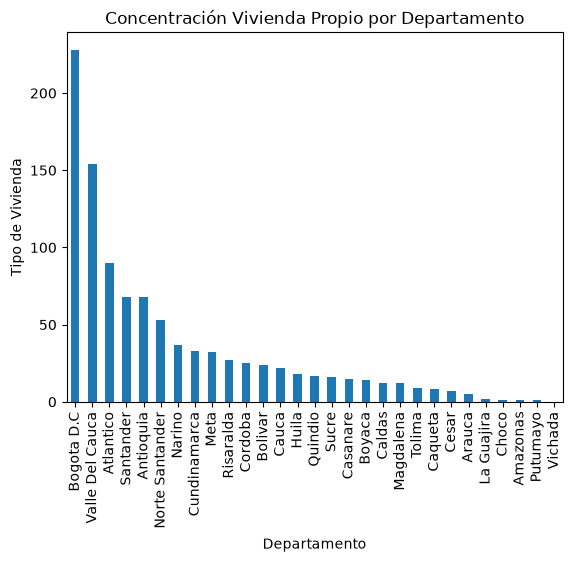

In [11]:
Ubicacion_TipoVivienda.plot(kind='bar')
plt.title('Concentración Vivienda Propio por Departamento')
plt.ylabel('Tipo de Vivienda')
plt.xlabel('Departamento')
plt.show()

In [12]:
Default_TipoVivienda = df.groupby('Tipo vivienda')['Default'].sum().sort_values(ascending = False)

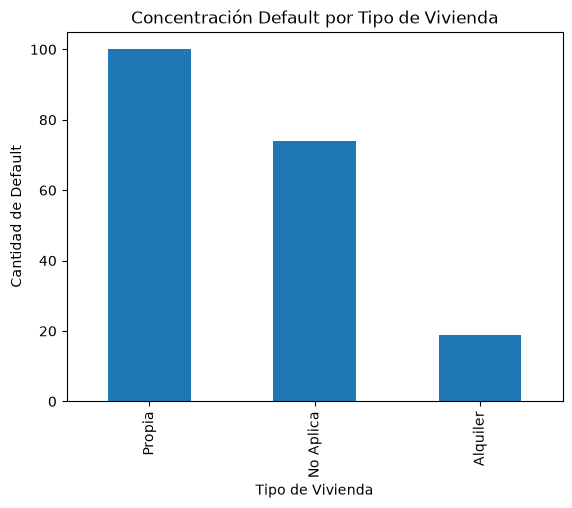

In [13]:
Ubicacion_TipoVivienda.plot(kind='bar')
plt.title('Concentración Default por Tipo de Vivienda')
plt.ylabel('Cantidad de Default')
plt.xlabel('Tipo de Vivienda')
plt.show()

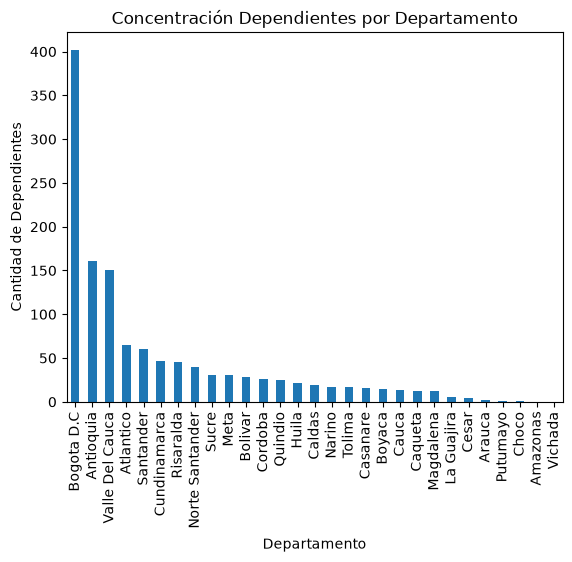

In [14]:
Ubicacion_Ocupacion.plot(kind='bar')
plt.title('Concentración Dependientes por Departamento')
plt.ylabel('Cantidad de Dependientes')
plt.xlabel('Departamento')
plt.show()

In [15]:
Default_Ocupacion =  df.groupby('Ocupación')['Default'].sum().sort_values(ascending = False)

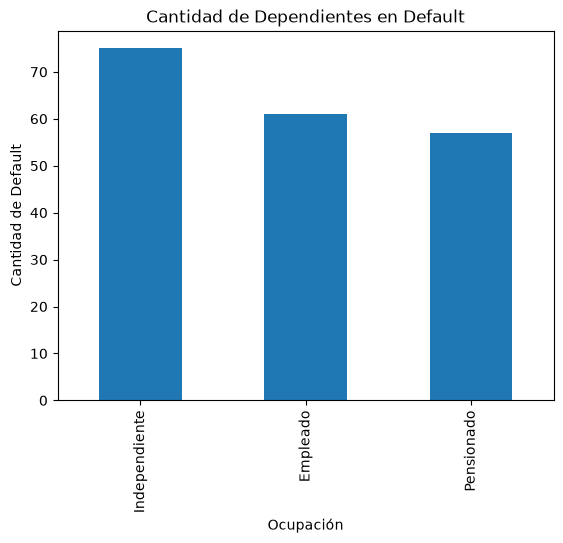

In [16]:
Default_Ocupacion.plot(kind='bar')
plt.title('Cantidad de Dependientes en Default')
plt.ylabel('Cantidad de Default')
plt.xlabel('Ocupación')
plt.show()

In [31]:
Default_Edad =  df.groupby('Rango Edad')['Default'].sum().sort_values(ascending = False)

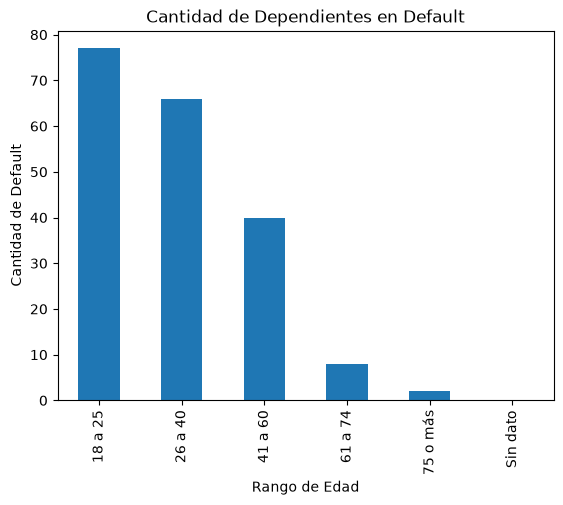

In [32]:
Default_Edad.plot(kind='bar')
plt.title('Cantidad de Dependientes en Default')
plt.ylabel('Cantidad de Default')
plt.xlabel('Rango de Edad')
plt.show()